## Importing libraries and data

In [ ]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import shap
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score

In [ ]:
train_data = pd.read_csv("/content/drive/MyDrive/Applied Machine Learning/AppML_InitialProject_train.csv")

In [ ]:
train_data.head()

,averageInteractionsPerCrossing,p_Rhad1,p_Rhad,p_f3,p_weta2,p_Rphi,p_Reta,p_Eratio,p_f1,p_TRTPID,...,pX_E7x11_Lr2,pX_E7x11_Lr3,pX_E7x7_Lr0,pX_E7x7_Lr1,p_pt_track,p_eta,p_phi,p_charge,p_Truth_isElectron,p_Truth_Energy
0,55.50,-0.002390,-0.003614,0.000744,0.010088,0.947685,0.983722,0.969448,0.355275,-0.030026,...,27951.328,473.046360,1415.2955,16208.0300,38339.875,0.725108,2.511338,-1.0,1,46673.574
1,33.50,-0.009279,-0.010666,0.003784,0.011625,0.922366,0.955934,0.918366,0.397633,0.335419,...,34642.820,86.462740,11456.5240,28639.7420,26470.890,1.566765,-0.593568,-1.0,1,85356.500
2,35.50,0.002806,0.013643,0.025505,0.010330,0.969845,0.945576,0.921568,0.077971,0.517517,...,88892.890,2173.160200,0.0000,8061.6840,32989.957,1.926261,2.497809,-1.0,1,103427.160
3,40.49,-0.001910,0.000044,0.000176,0.010323,0.923816,0.888029,0.000000,0.000000,0.133801,...,39768.450,102.033676,35418.3050,27154.4340,86615.234,1.510641,2.441266,-1.0,1,163799.640
4,52.50,0.013779,-0.002106,0.010156,0.010096,0.899883,0.717177,0.782584,0.253658,-0.044038,...,15531.818,277.199130,1242.5723,6206.0938,17362.506,-0.113342,3.003595,-1.0,1,16997.960


In [ ]:
train_data = train_data[train_data['p_Truth_isElectron']==1]

In [ ]:
train_data.describe()

,averageInteractionsPerCrossing,p_Rhad1,p_Rhad,p_f3,p_weta2,p_Rphi,p_Reta,p_Eratio,p_f1,p_TRTPID,...,pX_E7x11_Lr2,pX_E7x11_Lr3,pX_E7x7_Lr0,pX_E7x7_Lr1,p_pt_track,p_eta,p_phi,p_charge,p_Truth_isElectron,p_Truth_Energy
count,37800.000000,37800.000000,37800.000000,37800.000000,37800.000000,37800.000000,37800.000000,37800.000000,37800.000000,37800.000000,...,37800.000000,37800.000000,37800.000000,37800.000000,3.780000e+04,37800.000000,37800.000000,37800.000000,37800.0,37800.000000
mean,36.736413,0.047775,0.087398,0.012470,0.011190,0.883478,1.549753,0.776672,0.281378,0.180649,...,52283.108018,1526.155610,4972.406720,22745.130908,3.108338e+04,0.013645,0.003008,0.006561,1.0,64082.480382
std,10.714329,0.150799,0.268779,0.027438,0.003267,0.204615,124.471446,0.328216,0.115409,0.247621,...,44972.629963,4404.243441,6638.992497,16878.015023,2.357316e+05,1.364452,1.814017,0.999992,0.0,56220.127981
min,0.500000,-0.090331,-0.122811,-0.024949,-0.071970,-19.237244,-15.232583,0.000000,-0.006861,-0.633009,...,1562.752300,-1561.862400,-1605.905600,-61.309715,4.922555e+02,-2.523115,-3.140944,-1.000000,1.0,520.519170
25%,29.490000,-0.002074,-0.002626,0.004432,0.009789,0.851510,0.900521,0.763162,0.226318,-0.000000,...,25161.949000,135.986000,377.622392,11634.452500,1.057918e+04,-1.119742,-1.564403,-1.000000,1.0,28793.901000
50%,37.500000,0.002557,0.004178,0.006999,0.010553,0.932355,0.941301,0.947532,0.291805,0.129758,...,36162.041000,401.017010,2238.934350,16701.144500,2.760113e+04,0.029742,-0.015302,1.000000,1.0,49079.869000
75%,45.490000,0.018243,0.028802,0.011647,0.011891,0.958277,0.959206,0.974486,0.360119,0.296202,...,62139.298750,1060.545075,7261.878075,29079.565500,3.968141e+04,1.142721,1.576487,1.000000,1.0,81693.468000
max,59.500000,3.485963,6.071768,1.247175,0.075693,16.923542,24198.590000,1.000000,0.726255,2.295615,...,694601.250000,165806.940000,159025.270000,226605.310000,3.959646e+07,2.521093,3.141570,1.000000,1.0,871351.500000


In [ ]:
features = train_data.drop(columns=['p_Truth_isElectron','p_Truth_Energy'])
target = train_data['p_Truth_Energy']

features_labels = features.columns
target_labels = target.name

In [ ]:
features = features.astype(np.float32)
target = target.values.astype(np.float32)

In [ ]:
features_labels

Index(['averageInteractionsPerCrossing', 'p_Rhad1', 'p_Rhad', 'p_f3',
       'p_weta2', 'p_Rphi', 'p_Reta', 'p_Eratio', 'p_f1', 'p_TRTPID',
       ...
       'pX_E7x11_Lr0', 'pX_E7x11_Lr1', 'pX_E7x11_Lr2', 'pX_E7x11_Lr3',
       'pX_E7x7_Lr0', 'pX_E7x7_Lr1', 'p_pt_track', 'p_eta', 'p_phi',
       'p_charge'],
      dtype='object', length=140)

In [ ]:
# Split into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(features, target, test_size=0.25, random_state=42)

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

<ipython-input-11-fada0a3469d3>:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(X_train, labels=train_data.drop(columns=['p_Truth_isElectron', 'p_Truth_Energy']).columns)


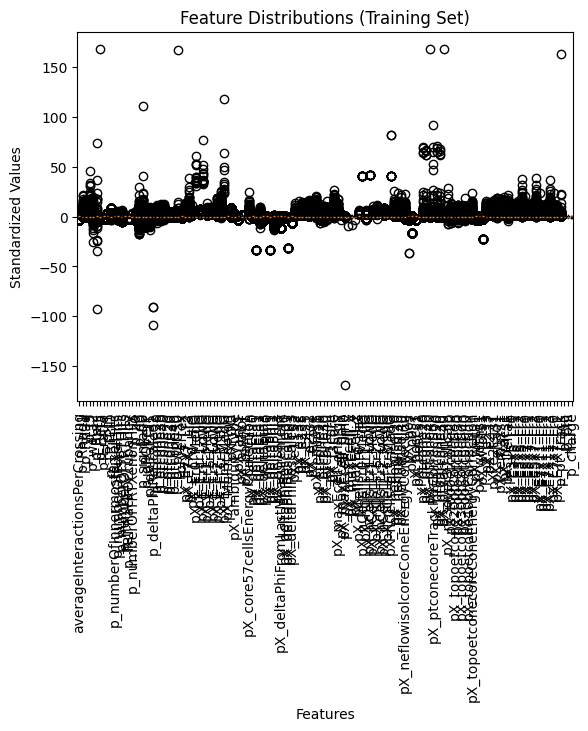

In [ ]:
# Visualize feature distributions
plt.boxplot(X_train, labels=train_data.drop(columns=['p_Truth_isElectron', 'p_Truth_Energy']).columns)
plt.xlabel("Features")
plt.ylabel("Standardized Values")
plt.xticks(rotation=90)
plt.title("Feature Distributions (Training Set)")
plt.show()

## Neural Network Model

In [ ]:
class RegressionDataset(Dataset):
    def __init__(self, features, target):
        self.features = features
        self.target = target

    def __len__(self):
        return len(self.features)

    def __getitem__(self, idx):
        return self.features[idx], self.target[idx]

In [ ]:
# Create datasets
train_dataset = RegressionDataset(X_train, y_train)
val_dataset = RegressionDataset(X_val, y_val)

In [ ]:
# Create data loaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

In [ ]:
class Model(nn.Module):
  def __init__(self, input_dim):
    super().__init__()
    self.fc1 = nn.Linear(input_dim, 128)
    self.dropout1 = nn.Dropout(0.2)
    self.fc2 = nn.Linear(128, 64)
    self.dropout2 = nn.Dropout(0.2)
    self.fc3 = nn.Linear(64, 1)

  def forward(self, x):
    x = nn.functional.relu(self.fc1(x))
    x = self.dropout1(x)
    x = nn.functional.relu(self.fc2(x))
    x = self.dropout2(x)
    x = self.fc3(x)
    return x

In [ ]:
model = Model(input_dim=X_train.shape[1])
criterion = nn.L1Loss()
optimizer = optim.Adam(model.parameters(), lr=0.01, weight_decay=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)

In [ ]:
# Training loop
num_epochs = 50
best_val_loss = float('inf')
patience = 10
counter = 0
for epoch in range(num_epochs):
    model.train()
    train_loss = 0
    for features, target in train_loader:
        optimizer.zero_grad()
        outputs = model(features)
        loss = criterion(outputs.squeeze(), target)  # Squeeze to match target shape
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    # Validation
    model.eval()
    val_loss = 0
    with torch.no_grad():
        for features, target in val_loader:
            outputs = model(features)
            loss = criterion(outputs.squeeze(), target)
            val_loss += loss.item()

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        counter = 0
        # Save best model
        torch.save(model.state_dict(), 'best_model.pth')
    else:
        counter += 1
    if counter >= patience:
        print("Early stopping triggered")
        break
    scheduler.step()
    print(f"Epoch {epoch+1}, Train Loss: {train_loss / len(train_loader):.4f}, Val Loss: {val_loss / len(val_loader):.4f}")

Epoch 1, Train Loss: 16875.6263, Val Loss: 9221.7329
Epoch 2, Train Loss: 11093.0897, Val Loss: 8367.9955
Epoch 3, Train Loss: 10631.9742, Val Loss: 8265.1042
Epoch 4, Train Loss: 10501.3663, Val Loss: 8405.3732
Epoch 5, Train Loss: 10403.8446, Val Loss: 7986.3354
Epoch 6, Train Loss: 10270.6530, Val Loss: 8217.6521
Epoch 7, Train Loss: 10134.0550, Val Loss: 8263.1138
Epoch 8, Train Loss: 10063.7355, Val Loss: 7915.7016
Epoch 9, Train Loss: 10044.0434, Val Loss: 8207.6278
Epoch 10, Train Loss: 9947.2999, Val Loss: 8059.7926
Epoch 11, Train Loss: 9676.7372, Val Loss: 7661.1720
Epoch 12, Train Loss: 9625.3585, Val Loss: 7638.5726
Epoch 13, Train Loss: 9656.7925, Val Loss: 7601.4901
Epoch 14, Train Loss: 9593.0076, Val Loss: 7582.4323
Epoch 15, Train Loss: 9581.7178, Val Loss: 7585.8991
Epoch 16, Train Loss: 9616.7640, Val Loss: 7606.3005
Epoch 17, Train Loss: 9575.4397, Val Loss: 7607.2912
Epoch 18, Train Loss: 9544.1237, Val Loss: 7627.7707
Epoch 19, Train Loss: 9543.0554, Val Loss: 757

In [ ]:
# Evaluate model
model.eval()
predictions = []
with torch.no_grad():
    for features, _ in val_loader:
        outputs = model(features)
        predictions.extend(outputs.squeeze().numpy())

In [ ]:
# Compute metrics
mae = mean_absolute_error(y_val, predictions)
r2 = r2_score(y_val, predictions)
print(f"\nValidation MAE: {mae:.4f}, R2: {r2:.4f}")


Validation MAE: 7546.7817, R2: 0.8828


In [ ]:
features

tensor([[ 0.3496, -0.2944, -0.2374,  ...,  1.5238, -0.0762, -1.0069],
        [-0.4874, -0.2898, -0.3217,  ...,  0.8254,  0.2329, -1.0069],
        [ 0.1643, -0.3220, -0.3286,  ...,  0.6623,  0.2794, -1.0069],
        ...,
        [ 1.0013, -0.3010, -0.3282,  ...,  0.7494, -0.3719, -1.0069],
        [ 0.5358, -0.2883, -0.2792,  ..., -0.8525, -1.4784,  0.9931],
        [-1.6047, -0.3419, -0.4124,  ..., -1.3571, -1.3116, -1.0069]])

In [ ]:
model.eval()
def model_predict(X):
  with torch.no_grad():
    X_tensor = torch.tensor(X, dtype=torch.float32)
    return model(X_tensor).squeeze().numpy()

In [ ]:
class PyTorchWrapper:
    def __init__(self, model, criterion, optimizer):
        self.model = model
        self.criterion = criterion
        self.optimizer = optimizer

    def fit(self, X, y, epochs=50):  # Example training loop
        X_tensor = torch.tensor(X, dtype=torch.float32)
        y_tensor = torch.tensor(y, dtype=torch.float32)
        dataset = RegressionDataset(X_tensor, y_tensor)
        loader = DataLoader(dataset, batch_size=32, shuffle=True)

        for epoch in range(epochs):
            self.model.train()
            train_loss = 0
            for features, target in loader:
                self.optimizer.zero_grad()
                outputs = self.model(features)
                loss = self.criterion(outputs.squeeze(), target)
                loss.backward()
                self.optimizer.step()
                train_loss += loss.item()

    def predict(self, X):
        with torch.no_grad():
            X_tensor = torch.tensor(X, dtype=torch.float32)
            return self.model(X_tensor).squeeze().numpy()

# Create the wrapper
wrapper = PyTorchWrapper(model, criterion, optimizer)

# Now use the wrapper with permutation_importance
perm_importance = permutation_importance(
    wrapper, X_val, y_val, scoring='neg_mean_absolute_error', n_repeats=10, random_state=42
)

In [ ]:
# Rank features by importance
p_importance_df = pd.DataFrame({
    'Feature': features_labels,
    'Importance': perm_importance.importances_mean
}).sort_values(by='Importance', ascending=False)

In [ ]:
p_importance_df.head(12)

,Feature,Importance
115,pX_e233,4372.192773
26,p_ptcone30,3779.299707
27,p_ptcone40,3677.752441
25,p_ptcone20,3444.726660
18,p_sigmad0,3040.540820
124,pX_E3x5_Lr2,2608.532617
34,pX_E_Lr1_HiG,2276.256445
63,pX_e235,2209.887793
123,pX_E3x5_Lr1,1943.020117
118,pX_ehad1,1642.313086


saving the variables

In [ ]:
pip install captum

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 20.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 32.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 76.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 64.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 38.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21

In [ ]:
from captum.attr import IntegratedGradients

In [ ]:
model.eval()
X_val_tensor = torch.tensor(X_val, dtype=torch.float32, requires_grad=True)


In [ ]:
ig = IntegratedGradients(model)

# اجرای attribution
attributions, delta = ig.attribute(inputs=X_val_tensor, target=None, return_convergence_delta=True)

# محاسبه میانگین مطلق importance برای هر ویژگی
avg_attr = attributions.abs().mean(dim=0).detach().numpy()


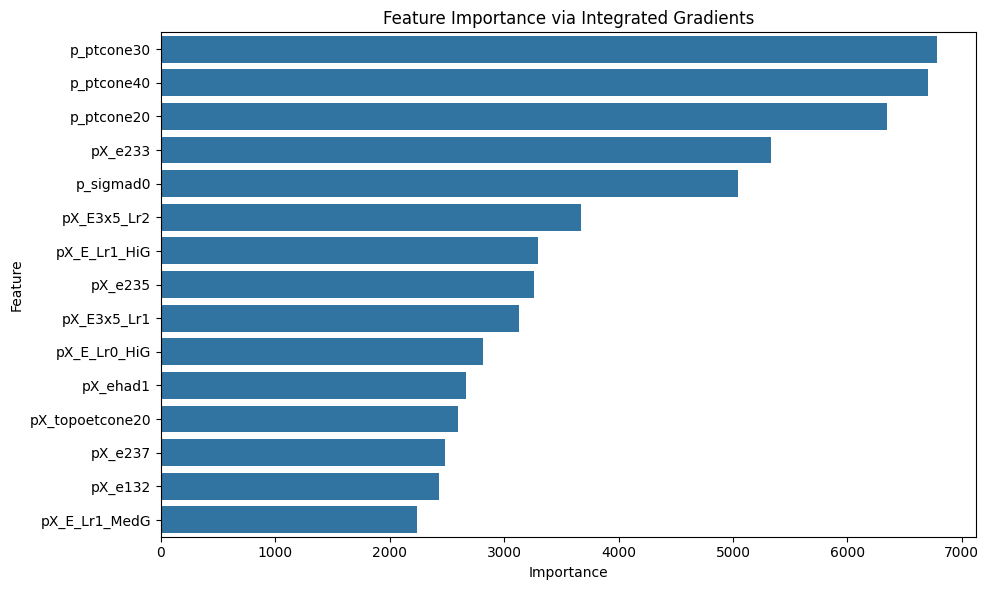

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

captum_importance_df = pd.DataFrame({
    'Feature': features_labels,
    'Importance': avg_attr
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=captum_importance_df.head(15))
plt.title('Feature Importance via Integrated Gradients')
plt.tight_layout()
plt.show()


In [ ]:
p_importance_df = p_importance_df.set_index('Feature').sort_index()
captum_importance_df = captum_importance_df.set_index('Feature').sort_index()

In [ ]:
# محاسبه رتبه‌ها
ranks_df = pd.DataFrame({
    'permutation': p_importance_df['Importance'].rank(ascending=False),
    'captum': captum_importance_df['Importance'].rank(ascending=False)
})

# میانگین رتبه‌ها
ranks_df['mean_rank'] = ranks_df.mean(axis=1)

rank_df = captum_importance_df['Importance'].sort_values(ascending=False)

# مرتب‌سازی و انتخاب top-12
#top_12_features = ranks_df.sort_values(by='mean_rank').head(12).index.tolist()
top_12_features = rank_df.head(12).index.tolist()
print("Top 12 features based on average rank:")
print(top_12_features)


Top 12 features based on average rank:
['p_ptcone30', 'p_ptcone40', 'p_ptcone20', 'pX_e233', 'p_sigmad0', 'pX_E3x5_Lr2', 'pX_E_Lr1_HiG', 'pX_e235', 'pX_E3x5_Lr1', 'pX_E_Lr0_HiG', 'pX_ehad1', 'pX_topoetcone20']


In [ ]:
variables_list = rank_df.head(12).index

In [ ]:
variables_list = pd.DataFrame(variables_list)
variables_list

,Feature
0,p_ptcone30
1,p_ptcone40
2,p_ptcone20
3,pX_e233
4,p_sigmad0
5,pX_E3x5_Lr2
6,pX_E_Lr1_HiG
7,pX_e235
8,pX_E3x5_Lr1
9,pX_E_Lr0_HiG


In [ ]:
variables_list.to_csv('/content/drive/MyDrive/Applied Machine Learning/Regression_MohammadhadiShahhosseini_VariablesList.csv', index=False)

In [ ]:
#feature_indices = [list(features_labels).index(f) for f in top_12_features]
#X_train_top12 = X_train[:, feature_indices]
#X_val_top12 = X_val[:, feature_indices]

features = train_data.drop(columns=['p_Truth_isElectron','p_Truth_Energy']).astype(np.float32)
features = features[top_12_features]
target = train_data['p_Truth_Energy'].values.astype(np.float32)

X_train_top12, X_val_top12, y_train, y_val = train_test_split(features, target, test_size=0.25, random_state=42)


In [ ]:
top_12_feature_names = top_12_features

In [ ]:
scaler_all = StandardScaler()
X_train_top12 = scaler_all.fit_transform(X_train_top12)
X_val_top12 = scaler_all.transform(X_val_top12)

<ipython-input-67-ca2af2bf8c30>:1: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(X_train_top12, labels=top_12_feature_names)


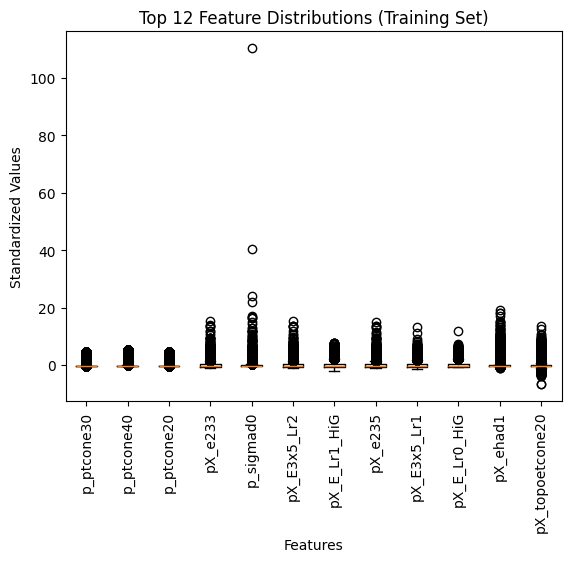

In [ ]:
plt.boxplot(X_train_top12, labels=top_12_feature_names)
plt.xlabel("Features")
plt.ylabel("Standardized Values")
plt.xticks(rotation=90)
plt.title("Top 12 Feature Distributions (Training Set)")
plt.show()

In [ ]:
# Create datasets with top 12 features
train_dataset_top12 = RegressionDataset(X_train_top12, y_train)
val_dataset_top12 = RegressionDataset(X_val_top12, y_val)

# Create data loaders
train_loader_top12 = DataLoader(train_dataset_top12, batch_size=32, shuffle=True)
val_loader_top12 = DataLoader(val_dataset_top12, batch_size=32, shuffle=False)

# Initialize and train model with top 12 features
model_top12 = Model(input_dim=X_train_top12.shape[1])
criterion = nn.L1Loss()  # Use MAE (L1 Loss)
optimizer = optim.Adagrad(model_top12.parameters(), lr=0.01)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)

In [ ]:
for epoch in range(num_epochs):
    model_top12.train()
    train_loss = 0
    for features, target in train_loader_top12:
        optimizer.zero_grad()
        outputs = model_top12(features)
        loss = criterion(outputs.squeeze(), target)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    # Validation
    model_top12.eval()
    val_loss = 0
    with torch.no_grad():
        for features, target in val_loader_top12:
            outputs = model_top12(features)
            loss = criterion(outputs.squeeze(), target)
            val_loss += loss.item()

    scheduler.step()
    print(f"Top 12 Features Model - Epoch {epoch+1}, Train Loss (MAE): {train_loss / len(train_loader_top12):.4f}, Val Loss (MAE): {val_loss / len(val_loader_top12):.4f}")

Top 12 Features Model - Epoch 1, Train Loss (MAE): 59927.1543, Val Loss (MAE): 53439.7426
Top 12 Features Model - Epoch 2, Train Loss (MAE): 46496.9899, Val Loss (MAE): 39454.6813
Top 12 Features Model - Epoch 3, Train Loss (MAE): 34892.3469, Val Loss (MAE): 30177.0622
Top 12 Features Model - Epoch 4, Train Loss (MAE): 27205.9492, Val Loss (MAE): 23295.6731
Top 12 Features Model - Epoch 5, Train Loss (MAE): 20868.6265, Val Loss (MAE): 17315.8394
Top 12 Features Model - Epoch 6, Train Loss (MAE): 15986.5735, Val Loss (MAE): 13436.6441
Top 12 Features Model - Epoch 7, Train Loss (MAE): 14172.7080, Val Loss (MAE): 12137.0466
Top 12 Features Model - Epoch 8, Train Loss (MAE): 13661.1245, Val Loss (MAE): 11673.0565
Top 12 Features Model - Epoch 9, Train Loss (MAE): 13496.8805, Val Loss (MAE): 11371.6818
Top 12 Features Model - Epoch 10, Train Loss (MAE): 13239.2723, Val Loss (MAE): 11161.8568
Top 12 Features Model - Epoch 11, Train Loss (MAE): 13159.0603, Val Loss (MAE): 11147.5428
Top 12 F

In [ ]:
# Evaluate model
model_top12.eval()
predictions = []
with torch.no_grad():
    for features, _ in val_loader_top12:
        outputs = model_top12(features)
        predictions.extend(outputs.squeeze().numpy())

# Compute metrics
mae = mean_absolute_error(y_val, predictions)
r2 = r2_score(y_val, predictions)
print(f"\nTop 12 Features Model - Validation MAE: {mae:.4f}, R2: {r2:.4f}")


Top 12 Features Model - Validation MAE: 11031.2900, R2: 0.8029


In [ ]:
!pip install optuna

In [ ]:
import optuna
import torch.nn.functional as F

def define_model(trial, input_dim):
    n_layers = trial.suggest_int('n_layers', 1, 3)
    layers = []
    in_features = input_dim

    for i in range(n_layers):
        out_features = trial.suggest_int(f'n_units_l{i}', 16, 128)
        layers.append(nn.Linear(in_features, out_features))
        layers.append(nn.BatchNorm1d(out_features))
        layers.append(nn.ReLU())
        dropout_rate = trial.suggest_float(f'dropout_l{i}', 0.1, 0.4)
        layers.append(nn.Dropout(dropout_rate))
        in_features = out_features

    layers.append(nn.Linear(in_features, 1))
    return nn.Sequential(*layers)

def objective(trial):
    # ساخت مدل با معماری پیشنهادی
    model = define_model(trial, input_dim=X_train_top12.shape[1])
    model = model.to('cpu')

    # انتخاب optimizer
    optimizer_name = trial.suggest_categorical("optimizer", ["Adam", "Adagrad", "RMSprop"])
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    optimizer = getattr(optim, optimizer_name)(model.parameters(), lr=lr)

    # loss
    criterion = nn.L1Loss()

    # training
    train_dataset = RegressionDataset(X_train_top12, y_train)
    val_dataset = RegressionDataset(X_val_top12, y_val)
    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

    for epoch in range(25):  # کم برای سرعت
        model.train()
        for batch_x, batch_y in train_loader:
            optimizer.zero_grad()
            preds = model(batch_x).squeeze()
            loss = criterion(preds, batch_y)
            loss.backward()
            optimizer.step()

    # evaluation
    model.eval()
    preds = []
    with torch.no_grad():
        for batch_x, _ in val_loader:
            pred = model(batch_x).squeeze()
            preds.extend(pred.numpy())

    # محاسبه MAE روی val set
    mae = mean_absolute_error(y_val, preds)
    return mae


In [ ]:
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=50)  # تعداد تکرارها

print("Best Trial:")
print(study.best_trial)

# نمایش بهترین پارامترها
for key, value in study.best_trial.params.items():
    print(f"{key}: {value}")


[I 2025-05-18 18:20:07,828] A new study created in memory with name: no-name-17c80840-1a90-479c-95d3-85c3f38f12cc
[I 2025-05-18 18:21:33,134] Trial 0 finished with value: 9959.865234375 and parameters: {'n_layers': 2, 'n_units_l0': 116, 'dropout_l0': 0.25725068616975255, 'n_units_l1': 125, 'dropout_l1': 0.39244202663462546, 'optimizer': 'Adam', 'lr': 0.006744515845301564}. Best is trial 0 with value: 9959.865234375.
[I 2025-05-18 18:22:30,527] Trial 1 finished with value: 15661.2822265625 and parameters: {'n_layers': 2, 'n_units_l0': 34, 'dropout_l0': 0.3917060763664514, 'n_units_l1': 33, 'dropout_l1': 0.2983146523994904, 'optimizer': 'Adam', 'lr': 0.005025091461489315}. Best is trial 0 with value: 9959.865234375.
[I 2025-05-18 18:23:32,692] Trial 2 finished with value: 63637.23828125 and parameters: {'n_layers': 3, 'n_units_l0': 48, 'dropout_l0': 0.3699412738475708, 'n_units_l1': 93, 'dropout_l1': 0.30972732623871724, 'n_units_l2': 60, 'dropout_l2': 0.21199139662271047, 'optimizer': '

Best Trial:
FrozenTrial(number=35, state=1, values=[9144.646484375], datetime_start=datetime.datetime(2025, 5, 18, 18, 52, 58, 654), datetime_complete=datetime.datetime(2025, 5, 18, 18, 54, 16, 934966), params={'n_layers': 3, 'n_units_l0': 107, 'dropout_l0': 0.19676922332300345, 'n_units_l1': 118, 'dropout_l1': 0.3484163887099468, 'n_units_l2': 96, 'dropout_l2': 0.3152939960416872, 'optimizer': 'Adam', 'lr': 0.0013161373993115116}, user_attrs={}, system_attrs={}, intermediate_values={}, distributions={'n_layers': IntDistribution(high=3, log=False, low=1, step=1), 'n_units_l0': IntDistribution(high=128, log=False, low=16, step=1), 'dropout_l0': FloatDistribution(high=0.4, log=False, low=0.1, step=None), 'n_units_l1': IntDistribution(high=128, log=False, low=16, step=1), 'dropout_l1': FloatDistribution(high=0.4, log=False, low=0.1, step=None), 'n_units_l2': IntDistribution(high=128, log=False, low=16, step=1), 'dropout_l2': FloatDistribution(high=0.4, log=False, low=0.1, step=None), 'opt

## Final Model

In [ ]:
class FinalOptunaModel(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, 107)
        self.bn1 = nn.BatchNorm1d(107)
        self.dropout1 = nn.Dropout(0.1968)

        self.fc2 = nn.Linear(107, 118)
        self.bn2 = nn.BatchNorm1d(118)
        self.dropout2 = nn.Dropout(0.3484)

        self.fc3 = nn.Linear(118, 96)
        self.bn3 = nn.BatchNorm1d(96)
        self.dropout3 = nn.Dropout(0.3153)

        self.out = nn.Linear(96, 1)

    def forward(self, x):
        x = F.relu(self.bn1(self.fc1(x)))
        x = self.dropout1(x)
        x = F.relu(self.bn2(self.fc2(x)))
        x = self.dropout2(x)
        x = F.relu(self.bn3(self.fc3(x)))
        x = self.dropout3(x)
        return self.out(x)


In [ ]:
# Assuming you already have:
# - X_train_top12_scaled
# - X_val_top12_scaled
# - y_train, y_val
# - scaler_top12
from torch.utils.data import TensorDataset, DataLoader

final_model = FinalOptunaModel(input_dim=X_train_top12.shape[1])
final_model = final_model.to("cpu")

criterion = nn.L1Loss()
optimizer = optim.Adam(final_model.parameters(), lr=0.0013161)
epochs = 50
batch_size = 32

train_dataset = TensorDataset(torch.tensor(X_train_top12, dtype=torch.float32),
                              torch.tensor(y_train, dtype=torch.float32))
val_dataset = TensorDataset(torch.tensor(X_val_top12, dtype=torch.float32),
                            torch.tensor(y_val, dtype=torch.float32))

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)


In [ ]:
for epoch in range(epochs):
    final_model.train()
    train_loss = 0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        preds = final_model(X_batch).squeeze()
        loss = criterion(preds, y_batch)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    final_model.eval()
    val_preds = []
    with torch.no_grad():
        for X_batch, _ in val_loader:
            pred = final_model(X_batch).squeeze()
            val_preds.extend(pred.numpy())

    val_mae = mean_absolute_error(y_val, val_preds)
    print(f"Epoch {epoch+1:02d} | Train MAE: {train_loss / len(train_loader):.4f} | Val MAE: {val_mae:.4f}")


Epoch 01 | Train MAE: 64022.4731 | Val MAE: 63477.9023
Epoch 02 | Train MAE: 63291.9460 | Val MAE: 62454.1055
Epoch 03 | Train MAE: 61998.9800 | Val MAE: 61044.1602
Epoch 04 | Train MAE: 60266.4428 | Val MAE: 58962.7344
Epoch 05 | Train MAE: 58103.8455 | Val MAE: 57108.3359
Epoch 06 | Train MAE: 55625.0641 | Val MAE: 54367.2500
Epoch 07 | Train MAE: 52881.0977 | Val MAE: 51690.3477
Epoch 08 | Train MAE: 49741.1143 | Val MAE: 48362.6016
Epoch 09 | Train MAE: 46323.8252 | Val MAE: 45140.1211
Epoch 10 | Train MAE: 42639.0324 | Val MAE: 40682.6445
Epoch 11 | Train MAE: 38917.9891 | Val MAE: 37231.8203
Epoch 12 | Train MAE: 35143.5981 | Val MAE: 33672.8320
Epoch 13 | Train MAE: 31396.2055 | Val MAE: 28665.7891
Epoch 14 | Train MAE: 27904.8184 | Val MAE: 36446.4609
Epoch 15 | Train MAE: 24644.5903 | Val MAE: 22551.4141
Epoch 16 | Train MAE: 21587.6011 | Val MAE: 18529.2734
Epoch 17 | Train MAE: 19038.7942 | Val MAE: 17692.7246
Epoch 18 | Train MAE: 17266.0746 | Val MAE: 12975.3223
Epoch 19 |

In [ ]:
# Final evaluation
final_model.eval()
preds = []
with torch.no_grad():
    for X_batch, _ in val_loader:
        pred = final_model(X_batch).squeeze()
        preds.extend(pred.numpy())

mae = mean_absolute_error(y_val, preds)
r2 = r2_score(y_val, preds)
print(f"\n✅ Final Model MAE: {mae:.4f}, R2: {r2:.4f}")

# Save model if needed
torch.save(final_model.state_dict(), "final_model_best_optuna.pth")



✅ Final Model MAE: 10592.9922, R2: 0.8687


In [ ]:
# Load unseen data
test_data = pd.read_csv("/content/drive/MyDrive/Applied Machine Learning/AppML_InitialProject_test_regression.csv")


In [ ]:
test_data.head()

,averageInteractionsPerCrossing,p_Rhad1,p_Rhad,p_f3,p_weta2,p_Rphi,p_Reta,p_Eratio,p_f1,p_TRTPID,...,pX_E7x11_Lr0,pX_E7x11_Lr1,pX_E7x11_Lr2,pX_E7x11_Lr3,pX_E7x7_Lr0,pX_E7x7_Lr1,p_pt_track,p_eta,p_phi,p_charge
0,16.5,0.308000,0.543823,0.021076,0.012767,0.477802,0.767441,0.283808,0.276458,-0.000000,...,0.00000,25144.729,61779.953,4150.57900,0.00000,16813.031,2043.1577,2.078785,2.527035,1.0
1,55.5,-0.006404,0.011466,0.007581,0.010188,0.926506,0.967169,0.947887,0.234617,0.189129,...,12707.74100,21856.750,55623.594,711.99493,12707.74100,21856.750,47284.1800,1.305989,-0.854433,1.0
2,38.5,0.001642,0.002910,0.010878,0.010648,0.949827,0.935892,0.985676,0.307103,0.346159,...,10488.42200,24370.460,45211.460,314.43726,10488.42200,24370.460,35586.1950,-1.519079,0.064510,-1.0
3,22.5,-0.000166,-0.000137,0.005283,0.009472,0.955001,0.940034,0.937368,0.292035,0.381448,...,976.79553,14721.353,35174.953,550.51860,976.79553,14721.353,44100.2400,-0.586419,-3.033514,1.0
4,37.5,-0.000825,-0.001584,0.005651,0.008775,0.962616,0.973497,0.955771,0.248332,0.209740,...,1873.40820,8583.128,25469.473,-171.68906,1873.40820,8583.128,29915.7520,0.747059,-0.650367,1.0


In [ ]:
# Select only top-12 features
X_test = test_data[top_12_features].astype(np.float32)

In [ ]:
X_test.head()

,p_ptcone30,p_ptcone40,p_ptcone20,pX_e233,p_sigmad0,pX_E3x5_Lr2,pX_E_Lr1_HiG,pX_e235,pX_E3x5_Lr1,pX_E_Lr0_HiG,pX_ehad1,pX_topoetcone20
0,16.000000,25.000000,15.000000,15675.992188,0.107424,28185.410156,16236.222656,26416.986328,14561.764648,0.000000,19221.689453,40160.105469
1,0.021889,0.021889,0.000000,50220.964844,0.012590,53272.289062,13488.548828,53407.945312,21120.150391,12003.426758,-490.549713,1058.501709
2,0.000000,0.000000,0.000000,40312.988281,0.012422,40556.066406,15589.342773,41840.980469,21979.640625,10199.728516,149.707779,-416.827637
3,0.000000,0.000000,0.000000,31315.974609,0.010843,32269.291016,14420.258789,32259.292969,13663.760742,1364.748413,-7.447038,-570.572754
4,0.104791,0.170275,0.062584,23846.005859,0.012827,24424.238281,9221.650391,24428.009766,8668.558594,2012.961670,-24.073427,678.405151


In [ ]:
# Assuming scaler_all was intended instead of scaler_top12
# and X_test instead of X_test_top12_raw
X_test_top12_scaled = scaler_all.transform(X_test)
X_test_tensor = torch.tensor(X_test_top12_scaled, dtype=torch.float32)

# Predict
final_model.eval()
with torch.no_grad():
    test_preds = final_model(X_test_tensor).squeeze().numpy()

In [ ]:
submission = pd.DataFrame({
    "ID": test_data.index,  # or test_data["ID"] if it exists
    "Predicted_p_Truth_Energy": test_preds
})
submission

,ID,Predicted_p_Truth_Energy
0,0,3215.935791
1,1,89829.882812
2,2,81967.812500
3,3,49558.460938
4,4,40862.796875
...,...,...
39995,39995,16503.953125
39996,39996,38011.003906
39997,39997,26588.960938
39998,39998,18193.007812


In [ ]:
submission.to_csv('/content/drive/MyDrive/Applied Machine Learning/Regression_MohammadhadiShahhosseini_NeuralNetwork.csv', index=False, header=False)